# Experiments 1 and 2, Step 4: representation benchmark and region-aware PSO (E. coli, Hospital A)

This notebook answers the supervisor's three stages on three antibiotics, one per class-balance group:

| Group | Antibiotic | Share resistant |
|---|---|---|
| Balanced | Ampicillin-Amoxicillin | 59.9% |
| Imbalanced | Ciprofloxacin | 28.5% |
| Extremely imbalanced | Cefepime | 7.6% |

| Part | Question | Output |
|---|---|---|
| **A. Experiment 1** | Which representation of the spectrum works best? Raw bins, kernels (linear, RBF) and variance-filtered bins (500 / 1,000 / 2,000), each with Logistic Regression, SVM and XGBoost | `exp1_<antibiotic>.csv` |
| **B. Experiment 2** | Can a region-aware PSO select a compact spectral signature that performs as well as the Experiment 1 inputs? | `pso_<antibiotic>.csv` |
| **C. Step 4** | Benchmark both experiments together and test whether the differences are real | Tables, tests, figures |

**Common rules (all parts)**
- Same data, same 5 saved folds (`fold_<antibiotic>`) and all isolates with an R/S label (intermediate results excluded).
- Everything that learns from data (scaler, kernel, variance filter, the PSO search) is fitted on the **training folds only**. The test fold is used once, for scoring.
- Metrics per test fold: AUROC, AUPRC (main metric, because resistance is the minority class for two of the three antibiotics), MCC and balanced accuracy at a fixed probability threshold of 0.5, and runtime.
- One row per fold is saved, so Step 4 can run statistical tests on the five fold values.


## 1. Settings

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import friedmanchisquare, rankdata
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.metrics.pairwise import linear_kernel, rbf_kernel
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             matthews_corrcoef, balanced_accuracy_score)
from xgboost import XGBClassifier            # install once with: %pip install xgboost
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"     # also silences warnings in the parallel workers

# ---------------- data and output ----------------
DATA_DIR    = "shared_data"                  # spectra_ecoli_A.npy and labels_ecoli_A.csv
OUT_DIR     = "results_final"
ANTIBIOTICS = ["Ampicillin-Amoxicillin", "Ciprofloxacin", "Cefepime"]
RUN_ABX     = ANTIBIOTICS                    # e.g. ["Cefepime"] to run one antibiotic on this laptop

# ---------------- evaluation (Parts A and B) ----------------
N_FOLDS   = 5
THRESHOLD = 0.5                              # fixed cut-off for MCC and balanced accuracy
FOLD_JOBS = 5                                # Part A: folds run in parallel
SEED      = 0

# ---------------- PSO (Part B) ----------------
REGION        = 10       # bins per region: 6,000 bins -> 600 regions
N_PARTICLES   = 20
N_ITERS       = 20
N_RESAMPLES   = 3        # stability: independent runs on 80% resamples of the training fold
SUBSAMPLE     = 0.8
MIN_VOTES     = 2        # a region enters the signature if chosen in >= 2 of the 3 runs
LAMBDA        = 0.05     # penalty on the share of regions kept
INNER_REPEATS = 2        # fitness: 2 x 3 inner folds
INIT_P        = 0.15     # average share of regions switched on at the start
SEED_REGIONS  = 30       # ANOVA starting particle: the 30 best regions
C1, C2, V_MAX = 2.0, 2.0, 4.0
ADAPTIVE      = True     # True = adaptive inertia + restarts; False = fixed inertia (standard PSO)
W_FIXED       = 0.7      # inertia when ADAPTIVE is False
W_MIN, W_MAX  = 0.4, 0.9 # adaptive inertia range
PATIENCE      = 5        # iterations without a new best set before restarting the worst half
SAFEGUARD     = True     # keep the PSO set only if it beats the ANOVA start on fresh training splits

os.makedirs(OUT_DIR, exist_ok=True)
N_CORES = os.cpu_count()
print("CPU cores:", N_CORES, "| antibiotics on this laptop:", RUN_ABX)

CPU cores: 16 | antibiotics on this laptop: ['Ampicillin-Amoxicillin', 'Ciprofloxacin', 'Cefepime']


## 2. Data and shared functions
- `get_abx_data` returns the spectra, labels and fold numbers of the isolates that have an R/S result for one antibiotic.
- `make_models` gives the three classifiers used in **both** experiments: Logistic Regression, SVM (RBF kernel on bins; the precomputed kernel on the kernel representations) and XGBoost. SVM uses `probability=True`, so every model returns a probability and the same 0.5 threshold applies to all.
- `score_models` trains the three models on the training fold and scores the test fold. It returns one row per model and the test-fold predictions (needed for the bootstrap in Step 4).

In [3]:
X   = np.load(f"{DATA_DIR}/spectra_ecoli_A.npy")
lab = pd.read_csv(f"{DATA_DIR}/labels_ecoli_A.csv")
print("spectra:", X.shape, "| labels:", lab.shape)

def get_abx_data(abx):
    has = lab[abx].notna() & (lab[f"fold_{abx}"] >= 0)
    return X[has.values], lab.loc[has, abx].astype(int).values, lab.loc[has, f"fold_{abx}"].values

for abx in ANTIBIOTICS:
    _, y_, f_ = get_abx_data(abx)
    print(f"{abx:24s} isolates {len(y_):5d} | resistant {y_.sum():5d} ({100 * y_.mean():.1f}%) | folds {sorted(set(f_))}")

def make_models(xgb_threads=-1, svm_kernel="rbf"):
    return {
        "lr":  LogisticRegression(max_iter=2000),
        "svm": SVC(kernel=svm_kernel, C=1.0, gamma="scale", probability=True, random_state=0),
        "xgb": XGBClassifier(n_estimators=300, tree_method="hist", n_jobs=xgb_threads,
                             random_state=0, eval_metric="logloss"),
    }

def score_models(Ztr, ytr, Zte, yte, xgb_threads=-1, kernel=False):
    # kernel=True: Ztr / Zte are kernel values between isolates and the training isolates.
    # SVM then uses them directly as a precomputed kernel; LR and XGBoost use them, standardised, as features.
    if kernel:
        ks = StandardScaler().fit(Ztr)
        feats = {"lr": (ks.transform(Ztr), ks.transform(Zte)), "xgb": (ks.transform(Ztr), ks.transform(Zte)),
                 "svm": (Ztr, Zte)}
    rows, preds = [], {}
    for name, model in make_models(xgb_threads, "precomputed" if kernel else "rbf").items():
        A, B = feats[name] if kernel else (Ztr, Zte)
        t = time.time()
        m = model.fit(A, ytr)
        fit_s = time.time() - t
        p = m.predict_proba(B)[:, 1]
        pred = (p >= THRESHOLD).astype(int)
        rows.append({"model": name,
                     "auroc": roc_auc_score(yte, p), "auprc": average_precision_score(yte, p),
                     "mcc": matthews_corrcoef(yte, pred), "bal_acc": balanced_accuracy_score(yte, pred),
                     "fit_seconds": fit_s})
        preds[name] = p
    return rows, preds

COLS = ["antibiotic", "fold", "representation", "model", "auroc", "auprc", "mcc", "bal_acc",
        "fit_seconds", "prep_seconds", "n_features"]

def save_preds(path, abx, k, rep, idx, yte, preds):
    # test-fold predictions: one line per isolate and model (used for the bootstrap in Step 4)
    df = pd.concat([pd.DataFrame({"antibiotic": abx, "fold": k, "representation": rep, "model": m,
                                  "idx": idx, "y": yte, "p": p}) for m, p in preds.items()])
    df.to_csv(path, mode="a", header=not os.path.exists(path), index=False)

spectra: (7320, 6000) | labels: (7320, 32)
Ampicillin-Amoxicillin   isolates  4866 | resistant  2913 (59.9%) | folds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Ciprofloxacin            isolates  4816 | resistant  1371 (28.5%) | folds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Cefepime                 isolates  4386 | resistant   335 (7.6%) | folds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


# Part A. Experiment 1: representation benchmark

| Representation | What it is | Features |
|---|---|---|
| `raw` | All bins, standardised | 6,000 |
| `kernel_linear` | Linear kernel: similarity of each isolate to every training isolate (dot product of the standardised spectra) | one per training isolate |
| `kernel_rbf` | RBF kernel: exp(−γ·distance²), γ = 1 / (number of bins × variance), the scikit-learn "scale" value | one per training isolate |
| `var500`, `var1000`, `var2000` | The 500 / 1,000 / 2,000 bins with the highest variance on the training fold; low-variance (uninformative) bins are dropped. Unsupervised: the labels are not used | 500 / 1,000 / 2,000 |

**How the kernels are used:** the SVM takes the kernel directly (`kernel="precomputed"`), which is the same as an SVM with a linear or RBF kernel. Logistic Regression and XGBoost receive the same kernel values, standardised, as their input features. All three models therefore see the same kernel representation.

**Variance filter:** the variance is computed on the raw intensities, before standardisation (after standardisation every bin has variance 1).

PIKE is not included (optional on the slides; it needs peak detection instead of binned spectra).

In [4]:
class KernelMap(BaseEstimator, TransformerMixin):
    # Kernel values between each isolate and the training isolates (fitted on the training fold)
    def __init__(self, kernel="rbf"):
        self.kernel = kernel
    def fit(self, X, y=None):
        self.Xtr_ = np.asarray(X)
        self.gamma_ = 1.0 / (X.shape[1] * self.Xtr_.var())          # scikit-learn "scale" value
        return self
    def transform(self, X):
        if self.kernel == "linear":
            return linear_kernel(X, self.Xtr_)
        return rbf_kernel(X, self.Xtr_, gamma=self.gamma_)

class TopVariance(BaseEstimator, TransformerMixin):
    # Keep the k bins with the highest variance on the training fold (labels not used)
    def __init__(self, k=1000):
        self.k = k
    def fit(self, X, y=None):
        self.keep_ = np.sort(np.argsort(-np.asarray(X).var(axis=0))[: self.k])
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.keep_]

# each representation = the preprocessing steps, in order (all fitted on the training fold)
REPRESENTATIONS = {
    "raw":           [StandardScaler()],
    "kernel_linear": [StandardScaler(), KernelMap("linear")],
    "kernel_rbf":    [StandardScaler(), KernelMap("rbf")],
    "var500":        [TopVariance(500), StandardScaler()],
    "var1000":       [TopVariance(1000), StandardScaler()],
    "var2000":       [TopVariance(2000), StandardScaler()],
}
KERNEL_REPS = {"kernel_linear", "kernel_rbf"}

### A.1 One fold of Experiment 1
The preprocessing steps are fitted on the training folds; `prep_seconds` is the time for that step, `fit_seconds` the training time of each model.

In [5]:
def exp1_fold(Xa, ya, fa, k, abx, rep, steps, xgb_threads):
    tr, te = fa != k, fa == k
    t = time.time()
    prep = make_pipeline(*[clone(s) for s in steps]).fit(Xa[tr], ya[tr])
    Ztr, Zte = prep.transform(Xa[tr]), prep.transform(Xa[te])
    prep_s = time.time() - t
    rows, preds = score_models(Ztr, ya[tr], Zte, ya[te], xgb_threads, kernel=rep in KERNEL_REPS)
    for r in rows:
        r.update(antibiotic=abx, fold=k, representation=rep, prep_seconds=prep_s, n_features=Ztr.shape[1])
    return rows, (k, np.flatnonzero(te), ya[te], preds)

### A.2 Pilot: one fold, raw bins

In [6]:
abx = RUN_ABX[0]
Xa, ya, fa = get_abx_data(abx)
t = time.time()
pilot_rows, _ = exp1_fold(Xa, ya, fa, 0, abx, "raw", REPRESENTATIONS["raw"], -1)
print(f"{abx}, fold 0, raw: {time.time() - t:.0f} s")
display(pd.DataFrame(pilot_rows)[COLS].round(3))

Ampicillin-Amoxicillin, fold 0, raw: 301 s


,antibiotic,fold,representation,model,auroc,auprc,mcc,bal_acc,fit_seconds,prep_seconds,n_features
0,Ampicillin-Amoxicillin,0,raw,lr,0.633,0.719,0.176,0.588,2.795,0.336,6000
1,Ampicillin-Amoxicillin,0,raw,svm,0.717,0.801,0.283,0.631,208.915,0.336,6000
2,Ampicillin-Amoxicillin,0,raw,xgb,0.693,0.796,0.202,0.596,76.400,0.336,6000


### A.3 Full run
The five folds run in parallel. Results are saved after every representation; finished representations are skipped if the cell is run again.

**Check against the ML phase:** `raw` with Logistic Regression should give the same AUROC as the baseline of the ML phase (Ciprofloxacin 0.786). Small differences in the other models are expected, because SVM now uses probabilities.

In [7]:
xgb_threads = max(1, N_CORES // FOLD_JOBS)
for abx in RUN_ABX:
    out, pred_out = f"{OUT_DIR}/exp1_{abx}.csv", f"{OUT_DIR}/exp1_preds_{abx}.csv"
    done = pd.read_csv(out) if os.path.exists(out) else pd.DataFrame(columns=COLS)
    Xa, ya, fa = get_abx_data(abx)
    for rep, steps in REPRESENTATIONS.items():
        if (done["representation"] == rep).any():
            print(f"{abx} | {rep}: already done, skipped"); continue
        t = time.time()
        res = Parallel(n_jobs=FOLD_JOBS)(delayed(exp1_fold)(Xa, ya, fa, k, abx, rep, steps, xgb_threads)
                                         for k in range(N_FOLDS))
        rows = [r for fold_rows, _ in res for r in fold_rows]
        done = pd.concat([done, pd.DataFrame(rows)[COLS]], ignore_index=True)
        done.to_csv(out, index=False)
        for _, (k, idx, yte, preds) in res:
            save_preds(pred_out, abx, k, rep, idx, yte, preds)
        m = pd.DataFrame(rows).groupby("model")[["auroc", "auprc"]].mean()
        print(f"{abx} | {rep:11s} | {(time.time() - t) / 60:4.1f} min | AUPRC "
              + "  ".join(f"{n} {v:.3f}" for n, v in m["auprc"].items()), flush=True)

Ampicillin-Amoxicillin | raw: already done, skipped
Ampicillin-Amoxicillin | kernel_linear: already done, skipped
Ampicillin-Amoxicillin | kernel_rbf: already done, skipped
Ampicillin-Amoxicillin | var500: already done, skipped
Ampicillin-Amoxicillin | var1000: already done, skipped
Ampicillin-Amoxicillin | var2000: already done, skipped
Ciprofloxacin | raw: already done, skipped
Ciprofloxacin | kernel_linear: already done, skipped
Ciprofloxacin | kernel_rbf: already done, skipped
Ciprofloxacin | var500: already done, skipped
Ciprofloxacin | var1000: already done, skipped
Ciprofloxacin | var2000: already done, skipped
Cefepime | raw: already done, skipped
Cefepime | kernel_linear: already done, skipped
Cefepime | kernel_rbf: already done, skipped
Cefepime | var500: already done, skipped
Cefepime | var1000: already done, skipped
Cefepime | var2000: already done, skipped


# Part B. Experiment 2: region-aware adaptive PSO

**Pipeline:** 6,000 bins → region-aware optimization → compact signature → AMR prediction.

The four improvements requested on the slides, and where each one is implemented:

| Improvement | Implementation | Function |
|---|---|---|
| **Region-aware binary encoding** | Neighbouring bins are grouped into 600 regions of 10 bins (30 Da). A particle is a 0/1 vector over regions | `bins_from_regions` |
| **Imbalance-aware objective** | Fitness = AUPRC of a class-balanced Logistic Regression, averaged over 2 × 3 inner folds of the training data, minus `LAMBDA` × share of regions kept | `fitness` |
| **Adaptive exploration–exploitation** | Inertia follows the swarm's diversity (spread out → high inertia, explore; close together → low inertia, exploit). If the best set does not change for `PATIENCE` iterations, the worst half of the swarm is restarted | `region_pso` |
| **Stability-guided selection** | The search runs 3 times on different 80% resamples of the training fold. Only regions chosen in at least 2 runs enter the signature | `stable_signature` |

**Search details**
- Binary PSO with a V-shaped transfer function: a bit flips with probability |tanh(velocity)|. Velocities start at 0.
- **Start:** each region is switched on with a probability that grows with its ANOVA score (training fold only), and one particle starts as the 30 best ANOVA regions. The search therefore begins from a sensible place and has to improve on it.
- **New inner split every iteration:** the inner folds change at each iteration, and the personal bests are re-scored on the same new split, so the swarm cannot memorise one split.
- **Safeguard:** after the search, the signature is kept only if it scores higher than the ANOVA starting set on fresh repeated splits of the training data. Otherwise the ANOVA set is used. How often this happens is reported.

**Evaluation:** the signature's bins go through the same three models, metrics and file format as Experiment 1 (`representation = "pso"`). `prep_seconds` is the time of the PSO search.

**Order (slide 6):** start with one antibiotic. Set `RUN_ABX = ["Ciprofloxacin"]` in section 1 before running Part B; run the other two after the supervisor's feedback.

**How the method was developed:** the components were developed step by step on single folds of Ciprofloxacin, Cefepime and Ampicillin-Amoxicillin.

In [8]:
N_REGIONS = X.shape[1] // REGION
MZ = 2000 + 3 * np.arange(X.shape[1])          # assumed bin -> m/z mapping (3 Da bins), to be confirmed

def bins_from_regions(mask):
    return np.repeat(np.asarray(mask).astype(bool), REGION)

def region_anova(Xtr, ytr, top=3):
    # ANOVA F per bin (training data), per region = mean of its 3 best bins
    F = np.nan_to_num(f_classif(Xtr, ytr)[0], nan=0.0, posinf=0.0, neginf=0.0).reshape(N_REGIONS, REGION)
    return np.sort(F, axis=1)[:, -top:].mean(1)

def anova_start(scores, n=SEED_REGIONS):
    m = np.zeros(N_REGIONS, dtype=int); m[np.argsort(-scores)[:n]] = 1
    return m

def fitness(mask, Xtr, ytr, seed, repeats=INNER_REPEATS):
    # imbalance-aware objective: class-balanced LR, AUPRC over repeats x 3 inner folds, minus size penalty
    keep = bins_from_regions(mask)
    if not keep.any():
        return -1.0
    scores = []
    for rep in range(repeats):
        for a, b in StratifiedKFold(3, shuffle=True, random_state=seed * 10 + rep).split(Xtr, ytr):
            m = LogisticRegression(max_iter=300, class_weight="balanced").fit(Xtr[a][:, keep], ytr[a])
            scores.append(average_precision_score(ytr[b], m.predict_proba(Xtr[b][:, keep])[:, 1]))
    return float(np.mean(scores) - LAMBDA * np.mean(mask))

### B.1 The adaptive region-aware PSO
`diversity` = share of bits in which the particles differ from the best set. The inertia is scaled by the diversity relative to the start: `w = W_MIN + (W_MAX − W_MIN) × min(1, diversity / diversity_start)`. With `ADAPTIVE = False`, the inertia is fixed at `W_FIXED` and there are no restarts (standard binary PSO).

In [9]:
def region_pso(Xtr, ytr, seed, start_sets=(), scores=None):
    rng = np.random.default_rng(seed)
    s = region_anova(Xtr, ytr) if scores is None else scores
    p_on = 0.02 + 0.98 * (s - s.min()) / (s.max() - s.min() + 1e-12)
    p_on = np.clip(p_on * INIT_P / p_on.mean(), 0.02, 0.6)

    def new_particles(n):
        P = (rng.random((n, N_REGIONS)) < p_on).astype(int)
        empty = P.sum(1) == 0
        P[empty, rng.integers(0, N_REGIONS, empty.sum())] = 1
        return P

    def evaluate(P, sd):
        return np.array(Parallel(n_jobs=-1)(delayed(fitness)(p, Xtr, ytr, sd) for p in P))

    pos = new_particles(N_PARTICLES)
    for i, sm in enumerate(start_sets):
        pos[i] = np.asarray(sm).astype(int)
    vel = np.zeros((N_PARTICLES, N_REGIONS))
    f = evaluate(pos, seed * 1000)
    pbest, pbest_f = pos.copy(), f.copy()
    g = int(np.argmax(pbest_f)); gbest = pbest[g].copy()
    div0 = max(float(np.mean(pos != gbest)), 1e-9)
    REF = 777                                                       # fixed reference split, for the convergence curve only
    stall = 0
    hist = [{"iter": 0, "best_fitness": float(pbest_f[g]), "best_fitness_ref": fitness(gbest, Xtr, ytr, REF),
             "mean_fitness": float(f.mean()), "inertia": np.nan, "diversity": div0,
             "n_regions": int(gbest.sum()), "restart": 0}]

    for it in range(N_ITERS):
        sd = seed * 1000 + it + 1                                   # new inner split this iteration
        div = float(np.mean(pos != gbest))
        w = W_MIN + (W_MAX - W_MIN) * min(1.0, div / div0) if ADAPTIVE else W_FIXED
        r1, r2 = rng.random(pos.shape), rng.random(pos.shape)
        vel = np.clip(w * vel + C1 * r1 * (pbest - pos) + C2 * r2 * (gbest - pos), -V_MAX, V_MAX)
        pos = np.where(rng.random(pos.shape) < np.abs(np.tanh(vel)), 1 - pos, pos)
        empty = pos.sum(1) == 0
        pos[empty, rng.integers(0, N_REGIONS, empty.sum())] = 1

        f = evaluate(pos, sd)
        pbest_f = evaluate(pbest, sd)                               # old bests re-scored on the same split
        better = f > pbest_f
        pbest[better], pbest_f[better] = pos[better], f[better]
        g = int(np.argmax(pbest_f))
        stall = 0 if not np.array_equal(pbest[g], gbest) else stall + 1
        gbest = pbest[g].copy()

        restart = 0
        if ADAPTIVE and stall >= PATIENCE:                          # stuck: restart the worst half
            worst = np.argsort(pbest_f)[: N_PARTICLES // 2]
            worst = worst[worst != g]
            pos[worst] = new_particles(len(worst)); vel[worst] = 0
            pbest[worst] = pos[worst]; pbest_f[worst] = evaluate(pos[worst], sd)
            stall, restart = 0, 1
        hist.append({"iter": it + 1, "best_fitness": float(pbest_f[g]),
                     "best_fitness_ref": fitness(gbest, Xtr, ytr, REF), "mean_fitness": float(f.mean()),
                     "inertia": w, "diversity": div, "n_regions": int(gbest.sum()), "restart": restart})
    return gbest, pd.DataFrame(hist)

### B.2 Stability-guided signature for one outer fold

In [10]:
def jaccard(masks):
    M = [np.asarray(m).astype(bool) for m in masks]
    v = [(M[i] & M[j]).sum() / max((M[i] | M[j]).sum(), 1) for i in range(len(M)) for j in range(i + 1, len(M))]
    return float(np.mean(v)) if v else 1.0

def stable_signature(Xtr, ytr, k):
    start = anova_start(region_anova(Xtr, ytr))
    masks, hists = [], []
    for r in range(N_RESAMPLES):
        sub = train_test_split(np.arange(len(ytr)), train_size=SUBSAMPLE, stratify=ytr,
                               random_state=SEED + 100 * k + r)[0]
        m, h = region_pso(Xtr[sub], ytr[sub], seed=SEED + 100 * k + r, start_sets=[start])
        masks.append(m); h["run"] = r; hists.append(h)
        print(f"   fold {k} run {r + 1}/{N_RESAMPLES}: {int(m.sum())} regions | "
              f"reference fitness {h['best_fitness_ref'].iloc[0]:.3f} -> {h['best_fitness_ref'].iloc[-1]:.3f} | "
              f"restarts {h['restart'].sum()}", flush=True)
    votes = np.array(masks).sum(0)
    sig = (votes >= MIN_VOTES).astype(int)
    if sig.sum() == 0:
        sig = (votes >= 1).astype(int)
    kept = "pso"
    if SAFEGUARD:
        f_sig, f_start = fitness(sig, Xtr, ytr, 99, repeats=5), fitness(start, Xtr, ytr, 99, repeats=5)
        if f_sig <= f_start:
            sig, kept = start, "anova_start"
    info = {"fold": k, "n_regions": int(sig.sum()), "kept": kept,
            "run_jaccard": jaccard(masks), "differs_from_start": int((sig != start).sum())}
    return sig, info, pd.concat(hists, ignore_index=True)

### B.3 Pilot: one outer fold
Check before the full run:
1. `best_fitness_ref` rises over the iterations: the best set scored on one fixed reference split (the search improves). `best_fitness` itself can go up and down, because it is scored on a new split every iteration.
2. The signature differs from the ANOVA start (`differs_from_start` > 0).
3. The time per fold.

In [11]:
abx = RUN_ABX[0]
Xa, ya, fa = get_abx_data(abx)
tr, te = fa != 0, fa == 0
sc = StandardScaler().fit(Xa[tr])
t = time.time()
sig0, info0, hist0 = stable_signature(sc.transform(Xa[tr]), ya[tr], 0)
print(f"\n{abx}, fold 0: {(time.time() - t) / 60:.1f} min | {info0}")
display(hist0[hist0.run == 0].round(3))

   fold 0 run 1/3: 46 regions | reference fitness 0.754 -> 0.769 | restarts 1
   fold 0 run 2/3: 48 regions | reference fitness 0.750 -> 0.757 | restarts 0
   fold 0 run 3/3: 42 regions | reference fitness 0.762 -> 0.767 | restarts 0

Ampicillin-Amoxicillin, fold 0: 36.5 min | {'fold': 0, 'n_regions': 28, 'kept': 'pso', 'run_jaccard': 0.26292171610893483, 'differs_from_start': 6}


,iter,best_fitness,best_fitness_ref,mean_fitness,inertia,diversity,n_regions,restart,run
0,0,0.753,0.754,0.707,NaN,0.137,30,0,0
1,1,0.762,0.761,0.742,0.900,0.137,44,0,0
2,2,0.761,0.754,0.734,0.675,0.076,30,0,0
3,3,0.765,0.761,0.748,0.729,0.090,44,0,0
4,4,0.757,0.757,0.722,0.618,0.060,42,0,0
5,5,0.774,0.763,0.748,0.808,0.112,37,0,0
6,6,0.765,0.763,0.731,0.635,0.065,37,0,0
7,7,0.766,0.766,0.742,0.746,0.095,46,0,0
8,8,0.766,0.766,0.725,0.680,0.077,46,0,0
9,9,0.763,0.766,0.742,0.764,0.100,46,0,0


### B.4 Full run: all outer folds
Per fold: scaler on the training folds → PSO signature (training folds only) → the three models on the signature's bins → score on the test fold. Saved after every fold; finished folds are skipped if the cell is run again.

Saved files per antibiotic: `pso_<abx>.csv` (same columns as Experiment 1), `pso_preds_<abx>.csv`, `pso_info_<abx>.csv` (signature size, safeguard result, run agreement), `pso_history_<abx>.csv` (convergence) and `pso_signature_<abx>_fold<k>.npy`.

In [12]:
for abx in RUN_ABX:
    out = f"{OUT_DIR}/pso_{abx}.csv"
    done = pd.read_csv(out) if os.path.exists(out) else pd.DataFrame(columns=COLS)
    Xa, ya, fa = get_abx_data(abx)
    for k in range(N_FOLDS):
        if (done["fold"] == k).any():
            print(f"{abx} fold {k}: already done, skipped"); continue
        tr, te = fa != k, fa == k
        sc = StandardScaler().fit(Xa[tr])
        Xtr, Xte = sc.transform(Xa[tr]), sc.transform(Xa[te])
        t = time.time()
        sig, info, hist = stable_signature(Xtr, ya[tr], k)
        search_s = time.time() - t
        keep = bins_from_regions(sig)
        rows, preds = score_models(Xtr[:, keep], ya[tr], Xte[:, keep], ya[te])
        for r in rows:
            r.update(antibiotic=abx, fold=k, representation="pso", prep_seconds=search_s, n_features=int(keep.sum()))
        done = pd.concat([done, pd.DataFrame(rows)[COLS]], ignore_index=True)
        done.to_csv(out, index=False)
        save_preds(f"{OUT_DIR}/pso_preds_{abx}.csv", abx, k, "pso", np.flatnonzero(te), ya[te], preds)
        np.save(f"{OUT_DIR}/pso_signature_{abx}_fold{k}.npy", sig)
        info.update(antibiotic=abx, search_minutes=search_s / 60)
        pd.DataFrame([info]).to_csv(f"{OUT_DIR}/pso_info_{abx}.csv", mode="a",
                                    header=not os.path.exists(f"{OUT_DIR}/pso_info_{abx}.csv"), index=False)
        hist["fold"] = k; hist["antibiotic"] = abx
        hist.to_csv(f"{OUT_DIR}/pso_history_{abx}.csv", mode="a",
                    header=not os.path.exists(f"{OUT_DIR}/pso_history_{abx}.csv"), index=False)
        print(f"{abx} fold {k}: {search_s / 60:.1f} min | {info['n_regions']} regions ({info['kept']}) | AUPRC "
              + "  ".join(f"{r['model']} {r['auprc']:.3f}" for r in rows) + "\n", flush=True)

Ampicillin-Amoxicillin fold 0: already done, skipped
Ampicillin-Amoxicillin fold 1: already done, skipped
Ampicillin-Amoxicillin fold 2: already done, skipped
Ampicillin-Amoxicillin fold 3: already done, skipped
Ampicillin-Amoxicillin fold 4: already done, skipped
Ciprofloxacin fold 0: already done, skipped
   fold 1 run 1/3: 34 regions | reference fitness 0.650 -> 0.654 | restarts 0
   fold 1 run 2/3: 39 regions | reference fitness 0.624 -> 0.630 | restarts 0
   fold 1 run 3/3: 40 regions | reference fitness 0.604 -> 0.602 | restarts 0
Ciprofloxacin fold 1: 31.5 min | 32 regions (pso) | AUPRC lr 0.720  svm 0.772  xgb 0.734

   fold 2 run 1/3: 39 regions | reference fitness 0.632 -> 0.657 | restarts 0
   fold 2 run 2/3: 40 regions | reference fitness 0.620 -> 0.642 | restarts 0
   fold 2 run 3/3: 42 regions | reference fitness 0.627 -> 0.635 | restarts 0
Ciprofloxacin fold 2: 30.0 min | 27 regions (pso) | AUPRC lr 0.649  svm 0.719  xgb 0.697

   fold 3 run 1/3: 38 regions | reference f

# Part C. Step 4: benchmarking and statistics

Reads the saved files only, so it can run on any laptop once Parts A and B are finished.

**Tests**
- **Friedman test** (per antibiotic and model): are the seven inputs different, using the five AUPRC fold values? Reported with the mean rank of each input (1 = best).
- **Bootstrap 95% confidence interval** for the AUPRC difference PSO − each Experiment 1 input: the test-fold predictions of all isolates are pooled, isolates are resampled 1,000 times, and the difference is recomputed each time. If the interval excludes 0, the difference is unlikely to be chance.
- A Wilcoxon test is not used: with 5 paired folds, its smallest possible two-sided p-value is 0.0625, so it can never reach 0.05.

In [13]:
N_BOOT = 1000
REP_ORDER = ["raw", "kernel_linear", "kernel_rbf", "var500", "var1000", "var2000", "pso"]
MODEL_ORDER = ["lr", "svm", "xgb"]

def load(prefix):
    fs = [f"{OUT_DIR}/{prefix}_{a}.csv" for a in ANTIBIOTICS if os.path.exists(f"{OUT_DIR}/{prefix}_{a}.csv")]
    return pd.concat([pd.read_csv(f) for f in fs], ignore_index=True) if fs else pd.DataFrame()

res = pd.concat([load("exp1"), load("pso")], ignore_index=True)
res["total_seconds"] = res["fit_seconds"] + res["prep_seconds"]
print("rows:", len(res), "| antibiotics:", sorted(res.antibiotic.unique()),
      "| representations:", sorted(res.representation.unique()))

rows: 315 | antibiotics: ['Ampicillin-Amoxicillin', 'Cefepime', 'Ciprofloxacin'] | representations: ['kernel_linear', 'kernel_rbf', 'pso', 'raw', 'var1000', 'var2000', 'var500']


### C.1 Main table: mean ± std over the 5 folds

In [14]:
def mean_std(metric):
    g = res.groupby(["antibiotic", "representation", "model"])[metric]
    t = (g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)).unstack("model")
    return t.reindex(columns=[m for m in MODEL_ORDER if m in t.columns])

for metric in ["auprc", "auroc", "mcc", "bal_acc"]:
    print(f"\n{metric.upper()} (mean ± std over 5 folds)")
    t = mean_std(metric).reset_index()
    t["representation"] = pd.Categorical(t["representation"], REP_ORDER, ordered=True)
    display(t.sort_values(["antibiotic", "representation"]).set_index(["antibiotic", "representation"]))

print("\nFeatures used and runtime per fold (seconds, mean over folds and models)")
display(res.groupby(["antibiotic", "representation"]).agg(n_features=("n_features", "mean"),
        prep_seconds=("prep_seconds", "mean"), fit_seconds=("fit_seconds", "mean")).round(1))


AUPRC (mean ± std over 5 folds)


model                                             lr            svm  \
antibiotic             representation                                 
Ampicillin-Amoxicillin raw             0.725 ± 0.015  0.792 ± 0.011   
                       kernel_linear   0.755 ± 0.019  0.717 ± 0.016   
                       kernel_rbf      0.803 ± 0.013  0.792 ± 0.011   
                       var500          0.756 ± 0.011  0.787 ± 0.011   
                       var1000          0.763 ± 0.02  0.805 ± 0.013   
                       var2000          0.74 ± 0.028  0.818 ± 0.012   
                       pso             0.765 ± 0.009    0.8 ± 0.008   
Cefepime               raw             0.403 ± 0.043  0.562 ± 0.087   
                       kernel_linear     0.43 ± 0.04  0.389 ± 0.055   
                       kernel_rbf       0.43 ± 0.087  0.562 ± 0.087   
                       var500          0.473 ± 0.081  0.531 ± 0.081   
                       var1000         0.423 ± 0.047  0.569 ± 0.082   
                       var2000         0.441 ± 0.049  0.609 ± 0.083   
                       pso             0.342 ± 0.039   0.52 ± 0.072   
Ciprofloxacin          raw             0.631 ± 0.017  0.747 ± 0.017   
                       kernel_linear   0.656 ± 0.018  0.606 ± 0.019   
                       kernel_rbf      0.731 ± 0.021  0.747 ± 0.017   
                       var500          0.566 ± 0.024   0.646 ± 0.02   
                       var1000         0.579 ± 0.017  0.706 ± 0.022   
                       var2000         0.615 ± 0.016   0.767 ± 0.02   
                       pso             0.685 ± 0.026  0.752 ± 0.022   

model                                            xgb  
antibiotic             representation                 
Ampicillin-Amoxicillin raw              0.801 ± 0.01  
                       kernel_linear   0.751 ± 0.017  
                       kernel_rbf      0.701 ± 0.018  
                       var500            0.8 ± 0.013  
                       var1000         0.816 ± 0.012  
                       var2000         0.814 ± 0.011  
                       pso              0.793 ± 0.01  
Cefepime               raw             0.541 ± 0.026  
                       kernel_linear   0.401 ± 0.084  
                       kernel_rbf       0.27 ± 0.066  
                       var500          0.479 ± 0.044  
                       var1000          0.488 ± 0.05  
                       var2000          0.542 ± 0.05  
                       pso               0.5 ± 0.054  
Ciprofloxacin          raw             0.757 ± 0.028  
                       kernel_linear    0.654 ± 0.03  
                       kernel_rbf      0.556 ± 0.025  
                       var500          0.647 ± 0.024  
                       var1000         0.706 ± 0.021  
                       var2000         0.762 ± 0.021  
                       pso             0.731 ± 0.025


AUROC (mean ± std over 5 folds)


model                                             lr            svm  \
antibiotic             representation                                 
Ampicillin-Amoxicillin raw             0.647 ± 0.019  0.714 ± 0.017   
                       kernel_linear   0.673 ± 0.017   0.64 ± 0.019   
                       kernel_rbf      0.723 ± 0.016  0.714 ± 0.017   
                       var500          0.668 ± 0.014  0.698 ± 0.014   
                       var1000         0.685 ± 0.021  0.721 ± 0.015   
                       var2000          0.67 ± 0.025  0.744 ± 0.014   
                       pso             0.674 ± 0.008  0.725 ± 0.003   
Cefepime               raw              0.84 ± 0.026  0.894 ± 0.017   
                       kernel_linear   0.864 ± 0.027  0.845 ± 0.029   
                       kernel_rbf      0.849 ± 0.031  0.894 ± 0.017   
                       var500           0.85 ± 0.023   0.85 ± 0.035   
                       var1000         0.847 ± 0.028  0.877 ± 0.035   
                       var2000          0.859 ± 0.02  0.894 ± 0.028   
                       pso             0.822 ± 0.009  0.876 ± 0.021   
Ciprofloxacin          raw             0.786 ± 0.006  0.826 ± 0.009   
                       kernel_linear   0.797 ± 0.013  0.775 ± 0.008   
                       kernel_rbf      0.831 ± 0.012  0.826 ± 0.009   
                       var500          0.756 ± 0.011  0.787 ± 0.014   
                       var1000         0.769 ± 0.003  0.822 ± 0.012   
                       var2000         0.791 ± 0.008  0.847 ± 0.015   
                       pso              0.805 ± 0.01  0.836 ± 0.017   

model                                            xgb  
antibiotic             representation                 
Ampicillin-Amoxicillin raw             0.709 ± 0.019  
                       kernel_linear   0.665 ± 0.022  
                       kernel_rbf      0.606 ± 0.021  
                       var500          0.711 ± 0.017  
                       var1000          0.73 ± 0.011  
                       var2000         0.728 ± 0.015  
                       pso             0.703 ± 0.011  
Cefepime               raw             0.884 ± 0.019  
                       kernel_linear    0.83 ± 0.031  
                       kernel_rbf      0.767 ± 0.014  
                       var500          0.838 ± 0.025  
                       var1000         0.853 ± 0.015  
                       var2000          0.884 ± 0.02  
                       pso             0.879 ± 0.024  
Ciprofloxacin          raw             0.842 ± 0.019  
                       kernel_linear   0.786 ± 0.023  
                       kernel_rbf      0.717 ± 0.018  
                       var500           0.79 ± 0.015  
                       var1000         0.822 ± 0.013  
                       var2000         0.851 ± 0.013  
                       pso             0.828 ± 0.014


MCC (mean ± std over 5 folds)


model                                             lr            svm  \
antibiotic             representation                                 
Ampicillin-Amoxicillin raw             0.211 ± 0.034  0.273 ± 0.031   
                       kernel_linear   0.242 ± 0.012  0.152 ± 0.018   
                       kernel_rbf      0.286 ± 0.029  0.273 ± 0.031   
                       var500          0.208 ± 0.029  0.238 ± 0.038   
                       var1000         0.262 ± 0.027   0.27 ± 0.012   
                       var2000         0.231 ± 0.033  0.333 ± 0.028   
                       pso             0.217 ± 0.014  0.303 ± 0.026   
Cefepime               raw             0.398 ± 0.047  0.496 ± 0.048   
                       kernel_linear   0.376 ± 0.045  0.254 ± 0.069   
                       kernel_rbf      0.281 ± 0.045  0.496 ± 0.048   
                       var500          0.424 ± 0.053  0.467 ± 0.043   
                       var1000          0.39 ± 0.024  0.536 ± 0.038   
                       var2000           0.4 ± 0.045  0.559 ± 0.062   
                       pso             0.348 ± 0.034  0.482 ± 0.061   
Ciprofloxacin          raw             0.408 ± 0.008  0.539 ± 0.023   
                       kernel_linear   0.425 ± 0.027  0.375 ± 0.024   
                       kernel_rbf      0.494 ± 0.033  0.539 ± 0.023   
                       var500          0.342 ± 0.016  0.428 ± 0.017   
                       var1000          0.381 ± 0.01  0.496 ± 0.039   
                       var2000          0.413 ± 0.02  0.576 ± 0.012   
                       pso             0.462 ± 0.032  0.539 ± 0.037   

model                                            xgb  
antibiotic             representation                 
Ampicillin-Amoxicillin raw             0.243 ± 0.041  
                       kernel_linear     0.2 ± 0.028  
                       kernel_rbf      0.124 ± 0.048  
                       var500          0.266 ± 0.015  
                       var1000         0.287 ± 0.017  
                       var2000         0.285 ± 0.023  
                       pso             0.245 ± 0.017  
Cefepime               raw             0.322 ± 0.041  
                       kernel_linear   0.241 ± 0.066  
                       kernel_rbf      0.139 ± 0.101  
                       var500          0.351 ± 0.039  
                       var1000         0.342 ± 0.027  
                       var2000         0.377 ± 0.044  
                       pso             0.368 ± 0.045  
Ciprofloxacin          raw             0.543 ± 0.024  
                       kernel_linear   0.426 ± 0.027  
                       kernel_rbf      0.311 ± 0.033  
                       var500          0.413 ± 0.032  
                       var1000         0.481 ± 0.024  
                       var2000         0.535 ± 0.022  
                       pso             0.509 ± 0.038


BAL_ACC (mean ± std over 5 folds)


model                                             lr            svm  \
antibiotic             representation                                 
Ampicillin-Amoxicillin raw             0.605 ± 0.016  0.625 ± 0.013   
                       kernel_linear   0.619 ± 0.006  0.559 ± 0.005   
                       kernel_rbf      0.636 ± 0.014  0.625 ± 0.013   
                       var500          0.602 ± 0.015  0.607 ± 0.019   
                       var1000          0.63 ± 0.013  0.625 ± 0.003   
                       var2000         0.616 ± 0.017  0.657 ± 0.011   
                       pso             0.604 ± 0.007  0.642 ± 0.011   
Cefepime               raw             0.669 ± 0.021   0.69 ± 0.018   
                       kernel_linear   0.643 ± 0.027  0.572 ± 0.024   
                       kernel_rbf      0.563 ± 0.014   0.69 ± 0.018   
                       var500          0.683 ± 0.024   0.668 ± 0.03   
                       var1000          0.69 ± 0.017   0.71 ± 0.023   
                       var2000         0.688 ± 0.023  0.723 ± 0.033   
                       pso             0.669 ± 0.026  0.686 ± 0.023   
Ciprofloxacin          raw             0.705 ± 0.006  0.734 ± 0.016   
                       kernel_linear   0.708 ± 0.014  0.658 ± 0.009   
                       kernel_rbf      0.701 ± 0.018  0.734 ± 0.016   
                       var500          0.659 ± 0.008   0.671 ± 0.01   
                       var1000         0.687 ± 0.007  0.707 ± 0.018   
                       var2000         0.709 ± 0.014  0.754 ± 0.013   
                       pso             0.711 ± 0.018  0.731 ± 0.022   

model                                            xgb  
antibiotic             representation                 
Ampicillin-Amoxicillin raw             0.614 ± 0.018  
                       kernel_linear   0.594 ± 0.012  
                       kernel_rbf      0.558 ± 0.022  
                       var500           0.626 ± 0.01  
                       var1000         0.636 ± 0.007  
                       var2000          0.636 ± 0.01  
                       pso             0.619 ± 0.007  
Cefepime               raw             0.578 ± 0.012  
                       kernel_linear   0.546 ± 0.018  
                       kernel_rbf      0.522 ± 0.015  
                       var500          0.596 ± 0.015  
                       var1000         0.597 ± 0.024  
                       var2000         0.604 ± 0.015  
                       pso             0.608 ± 0.021  
Ciprofloxacin          raw             0.721 ± 0.017  
                       kernel_linear    0.67 ± 0.016  
                       kernel_rbf      0.617 ± 0.014  
                       var500          0.666 ± 0.014  
                       var1000         0.699 ± 0.013  
                       var2000         0.721 ± 0.017  
                       pso             0.718 ± 0.024


Features used and runtime per fold (seconds, mean over folds and models)


n_features  prep_seconds  fit_seconds
antibiotic             representation                                       
Ampicillin-Amoxicillin kernel_linear       3892.8           3.5         77.9
                       kernel_rbf          3892.8           7.9         59.9
                       pso                  278.0        2109.5          2.3
                       raw                 6000.0           0.8        266.8
                       var1000             1000.0           0.4         43.3
                       var2000             2000.0           0.6         90.7
                       var500               500.0           0.3         20.0
Cefepime               kernel_linear       3508.8           2.6         31.0
                       kernel_rbf          3508.8           6.7         30.6
                       pso                  554.0        2185.8          2.8
                       raw                 6000.0           0.6        136.5
                       var1000             1000.0           0.3         14.2
                       var2000             2000.0           0.5         33.3
                       var500               500.0           0.3          6.2
Ciprofloxacin          kernel_linear       3852.8           3.5         63.2
                       kernel_rbf          3852.8           7.9         86.9
                       pso                  288.0        1688.3          3.3
                       raw                 6000.0           0.7        266.4
                       var1000             1000.0           0.4         34.6
                       var2000             2000.0           0.6         71.4
                       var500               500.0           0.4         15.9

### C.2 Friedman test and mean ranks (AUPRC)

In [15]:
rows = []
for (abx, model), d in res.groupby(["antibiotic", "model"]):
    wide = d.pivot(index="fold", columns="representation", values="auprc")
    wide = wide[[r for r in REP_ORDER if r in wide.columns]].dropna()
    stat, p = friedmanchisquare(*[wide[c].values for c in wide.columns])
    ranks = pd.DataFrame(rankdata(-wide.values, axis=1), columns=wide.columns).mean()
    rows.append({"antibiotic": abx, "model": model, "friedman_chi2": round(stat, 2), "p_value": round(p, 4),
                 **{f"rank_{c}": round(v, 1) for c, v in ranks.items()}})
display(pd.DataFrame(rows))

,antibiotic,model,friedman_chi2,p_value,rank_raw,rank_kernel_linear,rank_kernel_rbf,rank_var500,rank_var1000,rank_var2000,rank_pso
0,Ampicillin-Amoxicillin,lr,22.37,0.0010,6.8,3.8,1.0,4.4,3.2,5.6,3.2
1,Ampicillin-Amoxicillin,svm,25.54,0.0003,4.8,7.0,4.2,5.4,2.4,1.0,3.2
2,Ampicillin-Amoxicillin,xgb,26.66,0.0002,3.6,6.0,7.0,3.8,1.6,1.6,4.4
3,Cefepime,lr,15.51,0.0166,4.4,3.6,4.4,1.6,3.8,3.4,6.8
4,Cefepime,svm,22.63,0.0009,2.6,6.8,3.2,5.0,3.4,1.4,5.6
5,Cefepime,xgb,24.34,0.0005,1.6,5.6,7.0,4.4,4.2,1.8,3.4
6,Ciprofloxacin,lr,29.31,0.0001,4.2,3.0,1.0,6.8,6.2,4.8,2.0
7,Ciprofloxacin,svm,28.46,0.0001,3.2,7.0,3.4,6.0,5.0,1.0,2.4
8,Ciprofloxacin,xgb,28.97,0.0001,1.6,5.4,7.0,5.6,4.0,1.4,3.0


### C.3 Bootstrap confidence intervals: PSO vs each Experiment 1 input (AUPRC)

In [16]:
preds = pd.concat([load("exp1_preds"), load("pso_preds")], ignore_index=True)
rng = np.random.default_rng(0)
rows = []
for (abx, model), d in preds.groupby(["antibiotic", "model"]):
    wide = d.pivot_table(index=["fold", "idx"], columns="representation", values="p")
    y = d.drop_duplicates(["fold", "idx"]).set_index(["fold", "idx"]).loc[wide.index, "y"].values
    if "pso" not in wide.columns:
        continue
    boot_idx = [rng.integers(0, len(y), len(y)) for _ in range(N_BOOT)]
    for rep in [r for r in REP_ORDER if r in wide.columns and r != "pso"]:
        diff = average_precision_score(y, wide["pso"]) - average_precision_score(y, wide[rep])
        bs = [average_precision_score(y[b], wide["pso"].values[b]) - average_precision_score(y[b], wide[rep].values[b])
              for b in boot_idx]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        rows.append({"antibiotic": abx, "model": model, "pso_vs": rep, "auprc_diff": round(diff, 3),
                     "ci_low": round(lo, 3), "ci_high": round(hi, 3),
                     "verdict": "PSO better" if lo > 0 else ("PSO worse" if hi < 0 else "no clear difference")})
ci = pd.DataFrame(rows)
display(ci)

,antibiotic,model,pso_vs,auprc_diff,ci_low,ci_high,verdict
0,Ampicillin-Amoxicillin,lr,raw,0.040,0.024,0.055,PSO better
1,Ampicillin-Amoxicillin,lr,kernel_linear,0.010,-0.004,0.025,no clear difference
2,Ampicillin-Amoxicillin,lr,kernel_rbf,-0.039,-0.051,-0.026,PSO worse
3,Ampicillin-Amoxicillin,lr,var500,0.010,-0.005,0.025,no clear difference
4,Ampicillin-Amoxicillin,lr,var1000,0.003,-0.013,0.020,no clear difference
5,Ampicillin-Amoxicillin,lr,var2000,0.026,0.010,0.043,PSO better
6,Ampicillin-Amoxicillin,svm,raw,0.008,-0.002,0.019,no clear difference
7,Ampicillin-Amoxicillin,svm,kernel_linear,0.085,0.067,0.101,PSO better
8,Ampicillin-Amoxicillin,svm,kernel_rbf,0.008,-0.002,0.019,no clear difference
9,Ampicillin-Amoxicillin,svm,var500,0.014,0.001,0.025,PSO better


### C.4 PSO behaviour: signature size, safeguard and stability
- `kept`: whether the PSO set was used, or the safeguard fell back to the ANOVA start.
- `run_jaccard`: agreement between the 3 runs inside a fold (1 = identical).
- Between-fold stability: agreement of the final signatures across the 5 folds.

In [17]:
info = load("pso_info")
display(info[["antibiotic", "fold", "n_regions", "kept", "differs_from_start", "run_jaccard", "search_minutes"]].round(2))
for abx in ANTIBIOTICS:
    sigs = [np.load(f"{OUT_DIR}/pso_signature_{abx}_fold{k}.npy") for k in range(N_FOLDS)
            if os.path.exists(f"{OUT_DIR}/pso_signature_{abx}_fold{k}.npy")]
    if sigs:
        print(f"{abx:24s} between-fold Jaccard of the signatures: {jaccard(sigs):.2f}")

,antibiotic,fold,n_regions,kept,differs_from_start,run_jaccard,search_minutes
0,Ampicillin-Amoxicillin,0,28,pso,6,0.26,33.78
1,Ampicillin-Amoxicillin,1,33,pso,13,0.24,38.92
2,Ampicillin-Amoxicillin,2,24,pso,14,0.26,35.87
3,Ampicillin-Amoxicillin,3,26,pso,8,0.37,27.80
4,Ampicillin-Amoxicillin,4,28,pso,6,0.26,39.43
5,Ciprofloxacin,0,28,pso,6,0.36,24.95
6,Ciprofloxacin,1,32,pso,4,0.40,31.47
7,Ciprofloxacin,2,27,pso,5,0.37,29.97
8,Ciprofloxacin,3,29,pso,1,0.47,25.98
9,Ciprofloxacin,4,28,pso,2,0.48,28.33


Ampicillin-Amoxicillin   between-fold Jaccard of the signatures: 0.45
Ciprofloxacin            between-fold Jaccard of the signatures: 0.73
Cefepime                 between-fold Jaccard of the signatures: 0.23


### C.5 Figures
1. AUPRC of every input, per model and antibiotic (bars = mean, lines = std over folds).
2. PSO convergence on fold 0: fitness of the best set on a fixed reference split per iteration, inertia (dashed), and restarts (×).
3. Regions in the PSO signature along the spectrum: share of folds in which each region was selected. **The m/z axis assumes 3 Da bins from 2,000 Da; this mapping is still to be confirmed.**

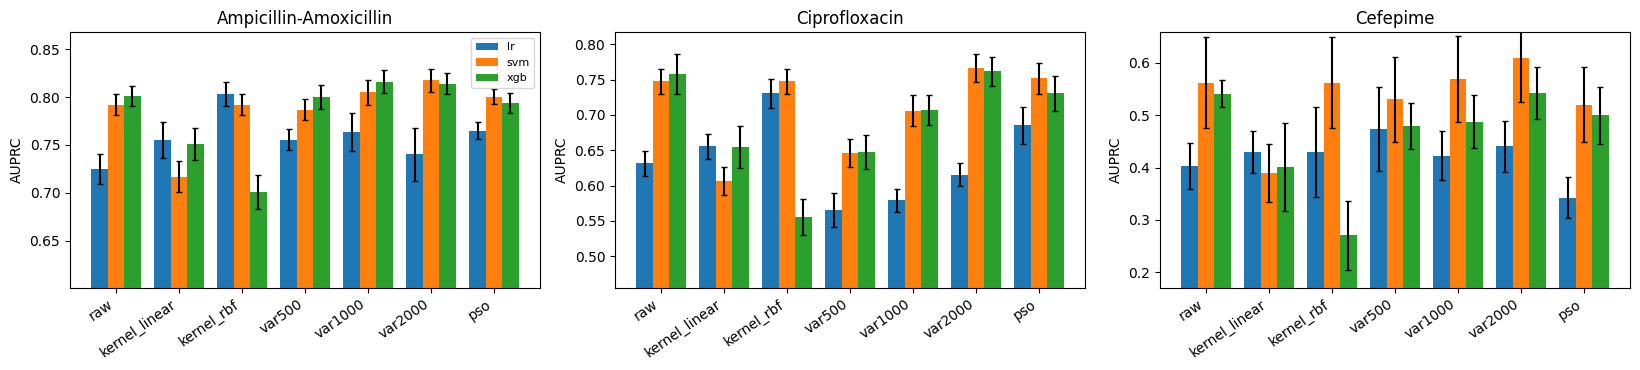

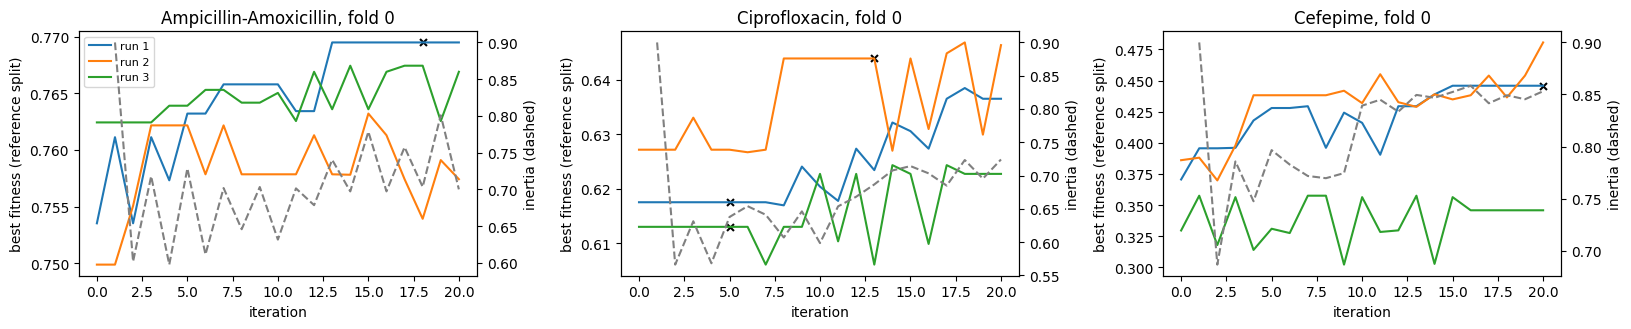

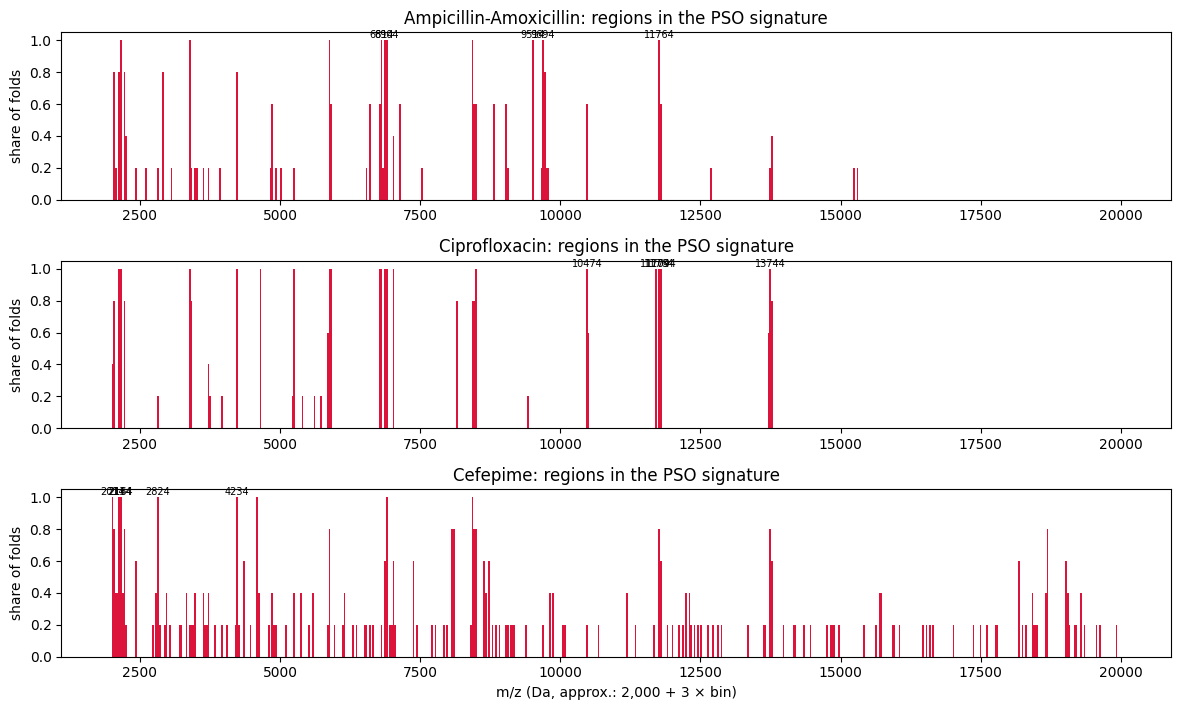

Regions selected in all 5 folds (approx. Da):
  Ampicillin-Amoxicillin: 2150-2180, 3380-3410, 5870-5900, 6800-6830, 6860-6890, 6890-6920, 8420-8450, 9500-9530, 9680-9710, 11750-11780
  Ciprofloxacin: 2120-2150, 2150-2180, 3380-3410, 4220-4250, 4640-4670, 5240-5270, 5870-5900, 5900-5930, 6770-6800, 6800-6830, 6860-6890, 6890-6920, 7010-7040, 8480-8510, 10460-10490, 11690-11720, 11750-11780, 11780-11810, 13730-13760
  Cefepime: 2000-2030, 2120-2150, 2150-2180, 2810-2840, 4220-4250, 4580-4610, 6890-6920, 8420-8450


In [18]:
abx_list = [a for a in ANTIBIOTICS if a in res.antibiotic.unique()]
fig, axes = plt.subplots(1, len(abx_list), figsize=(5.5 * len(abx_list), 3.8), squeeze=False)
for ax, abx in zip(axes[0], abx_list):
    d = res[res.antibiotic == abx].groupby(["representation", "model"]).auprc.agg(["mean", "std"]).reset_index()
    reps = [r for r in REP_ORDER if r in d.representation.unique()]
    x = np.arange(len(reps)); wdt = 0.26
    for i, mdl in enumerate([m for m in MODEL_ORDER if m in d.model.unique()]):
        dm = d[d.model == mdl].set_index("representation").reindex(reps)
        ax.bar(x + (i - 1) * wdt, dm["mean"], wdt, yerr=dm["std"], capsize=2, label=mdl)
    ax.set_xticks(x); ax.set_xticklabels(reps, rotation=35, ha="right")
    ax.set_title(abx); ax.set_ylabel("AUPRC")
    ax.set_ylim(max(0, d["mean"].min() - 0.1), min(1, d["mean"].max() + 0.05))
axes[0][0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_auprc.png", dpi=200); plt.show()

hist = load("pso_history")
if len(hist):
    fig, axes = plt.subplots(1, len(abx_list), figsize=(5.5 * len(abx_list), 3.4), squeeze=False)
    for ax, abx in zip(axes[0], abx_list):
        h = hist[(hist.antibiotic == abx) & (hist.fold == 0)]
        for r, g in h.groupby("run"):
            ax.plot(g["iter"], g["best_fitness_ref"], label=f"run {r + 1}")
            rs = g[g.restart == 1]; ax.scatter(rs["iter"], rs["best_fitness_ref"], marker="x", c="k", s=25)
        ax2 = ax.twinx(); ax2.plot(h.groupby("iter").inertia.mean(), "--", c="grey"); ax2.set_ylabel("inertia (dashed)")
        ax.set_title(f"{abx}, fold 0"); ax.set_xlabel("iteration"); ax.set_ylabel("best fitness (reference split)")
    axes[0][0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_convergence.png", dpi=200); plt.show()

centre = np.array([MZ[r * REGION: (r + 1) * REGION].mean() for r in range(N_REGIONS)])
fig, axes = plt.subplots(len(abx_list), 1, figsize=(12, 2.4 * len(abx_list)), squeeze=False)
for ax, abx in zip(axes[:, 0], abx_list):
    sigs = [np.load(f"{OUT_DIR}/pso_signature_{abx}_fold{k}.npy") for k in range(N_FOLDS)
            if os.path.exists(f"{OUT_DIR}/pso_signature_{abx}_fold{k}.npy")]
    if not sigs:
        continue
    freq = np.mean(sigs, axis=0)
    ax.bar(centre, freq, width=3 * REGION, color="crimson")
    ax.set_ylabel("share of folds"); ax.set_title(f"{abx}: regions in the PSO signature")
    for r in np.argsort(-freq)[:5]:
        if freq[r] > 0:
            ax.annotate(f"{centre[r]:.0f}", (centre[r], freq[r]), fontsize=7, ha="center", va="bottom")
axes[-1, 0].set_xlabel("m/z (Da, approx.: 2,000 + 3 × bin)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_regions.png", dpi=200); plt.show()

print("Regions selected in all 5 folds (approx. Da):")
for abx in abx_list:
    sigs = [np.load(f"{OUT_DIR}/pso_signature_{abx}_fold{k}.npy") for k in range(N_FOLDS)
            if os.path.exists(f"{OUT_DIR}/pso_signature_{abx}_fold{k}.npy")]
    if len(sigs) == N_FOLDS:
        allf = np.flatnonzero(np.all(sigs, axis=0))
        print(f"  {abx}: " + ", ".join(f"{MZ[r * REGION]:.0f}-{MZ[r * REGION + REGION - 1] + 3:.0f}" for r in allf))

## Results and observations
*(Fill in after the run, from the tables above. Write only what the tables show.)*

- **Experiment 1:** which representation and model gave the best AUPRC for each antibiotic, and the runtime cost of each representation.
- **Experiment 2:** signature size (regions and bins), whether the PSO matched or beat the Experiment 1 inputs (bootstrap verdicts), how often the safeguard fell back to the ANOVA start, and the stability between folds.
- **Step 4:** Friedman p-values and mean ranks.

**Limits:** one hospital; 5 folds; the m/z mapping of the bins is assumed (2,000 + 3 × bin); the PSO was developed on single folds of the same three antibiotics before the final run.